**Team:** Leandro Alexis & Dayana Guerrero

**Dataset:** Global Super Store (Kaggle) – 51,290 order lines, 24 columns

**Business question:** Why do some products and markets generate high sales but low or negative profit?

In [1]:
# ============================================================
# 1. SETUP: libraries, visual style and color palettes
# ============================================================
import os
import warnings
warnings.filterwarnings("ignore")      

import numpy as np                      
import pandas as pd                     
import matplotlib as mpl
import matplotlib.pyplot as plt        
import seaborn as sns                   
import plotly.express as px             

os.makedirs("exports", exist_ok=True)   

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.25,
    "figure.dpi": 110,
    "savefig.dpi": 300,                 
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

CAT3 = ["#2a78d6", "#eb6834", "#1baf7a"]                       
CAT7 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
        "#e87ba4", "#008300", "#6250d6"]                        
SEQ = "viridis"                                                
DIV = "RdBu"                                                   

def save(fig, name):
    """Export a Matplotlib figure as high-resolution PNG and vector SVG."""
    fig.savefig(f"exports/{name}.png", bbox_inches="tight")
    fig.savefig(f"exports/{name}.svg", bbox_inches="tight")
    print(f"Saved: exports/{name}.png and exports/{name}.svg")

print("Setup complete")

Setup complete


In [2]:
# ============================================================
# 2. LOAD THE RAW DATASET
# ============================================================
df_raw = pd.read_csv("data/Global_Superstore2.csv", encoding="latin-1")
print("Rows, columns:", df_raw.shape)
df_raw.head()

Rows, columns: (51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


## Data Profiling
Checking data types, missing values and duplicates before cleaning.

In [3]:
# ============================================================
# 3. DATA PROFILING: types, missing values, duplicates
# ============================================================
df_raw.info()

missing = df_raw.isnull().sum()
missing_table = pd.DataFrame({"missing": missing,
                              "percent": (missing / len(df_raw) * 100).round(2)})
display(missing_table[missing_table["missing"] > 0])

print("Exact duplicated rows:", df_raw.duplicated().sum())

df_raw.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  str    
 2   Order Date      51290 non-null  str    
 3   Ship Date       51290 non-null  str    
 4   Ship Mode       51290 non-null  str    
 5   Customer ID     51290 non-null  str    
 6   Customer Name   51290 non-null  str    
 7   Segment         51290 non-null  str    
 8   City            51290 non-null  str    
 9   State           51290 non-null  str    
 10  Country         51290 non-null  str    
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  str    
 13  Region          51290 non-null  str    
 14  Product ID      51290 non-null  str    
 15  Category        51290 non-null  str    
 16  Sub-Category    51290 non-null  str    
 17  Product Name    51290 non-null  str    
 1

,missing,percent
Postal Code,41296,80.51


Exact duplicated rows: 0


,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00,9994.00,51290.00,51290.00,51290.00,51290.00,51290.00
mean,25645.50,55190.38,246.49,3.48,0.14,28.61,26.38
std,14806.29,32063.69,487.57,2.28,0.21,174.34,57.30
min,1.00,1040.00,0.44,1.00,0.00,-6599.98,0.00
25%,12823.25,23223.00,30.76,2.00,0.00,0.00,2.61
50%,25645.50,56430.50,85.05,3.00,0.00,9.24,7.79
75%,38467.75,90008.00,251.05,5.00,0.20,36.81,24.45
max,51290.00,99301.00,22638.48,14.00,0.85,8399.98,933.57


## Data Cleaning & Missing Value Imputation
- Column names standardized, dates parsed, numeric types enforced, duplicates removed.
- **Postal Code** is only recorded for US orders (80.5% missing), so it is *structurally* missing: we flag it and fill with "N/A" instead of inventing codes.
- Numeric gaps are filled with the **median of the same Sub-Category** (robust to outliers).

In [4]:
# ============================================================
# 4. DATA CLEANING AND MISSING VALUE IMPUTATION
# ============================================================
df = df_raw.copy()

df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")

for c in ["Order_Date", "Ship_Date"]:
    df[c] = pd.to_datetime(df[c], dayfirst=True, format="mixed", errors="coerce")
print("Dates that could not be parsed:", df[["Order_Date", "Ship_Date"]].isnull().sum().to_dict())

num_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping_Cost"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for c in text_cols:
    df[c] = df[c].str.strip()

before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

df["Postal_Code_Missing"] = df["Postal_Code"].isnull()
df["Postal_Code"] = (pd.to_numeric(df["Postal_Code"], errors="coerce")
                     .round().astype("Int64").astype("string").fillna("N/A"))

for c in num_cols:
    df[c] = df[c].fillna(df.groupby("Sub_Category")[c].transform("median"))

for c in text_cols:
    if c != "Postal_Code":
        df[c] = df[c].fillna("Unknown")

med_days = (df["Ship_Date"] - df["Order_Date"]).dt.days.groupby(df["Ship_Mode"]).transform("median")
df["Ship_Date"] = df["Ship_Date"].fillna(df["Order_Date"] + pd.to_timedelta(med_days, unit="D"))

df = df.dropna(subset=["Order_Date"])

print("Remaining missing values:", int(df.isnull().sum().sum()))
print("Clean shape:", df.shape)

Dates that could not be parsed: {'Order_Date': 0, 'Ship_Date': 0}
Duplicates removed: 0
Remaining missing values: 0
Clean shape: (51290, 25)


In [5]:
# ============================================================
# 5. FEATURE ENGINEERING + EXPORT CLEAN DATA (for Power BI)
# ============================================================
df["Year"] = df["Order_Date"].dt.year                                   
df["Month"] = df["Order_Date"].dt.month                                 
df["Quarter_Start"] = df["Order_Date"].dt.to_period("Q").dt.to_timestamp()   
df["Year_Month"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()     
df["Ship_Days"] = (df["Ship_Date"] - df["Order_Date"]).dt.days          
df["Profit_Margin"] = df["Profit"] / df["Sales"]                      
df["Is_Loss"] = df["Profit"] < 0                                      
df["Discount_Band"] = pd.cut(df["Discount"],                            
                             bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.5, 1.0],
                             labels=["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"])

print("Ship days range:", df["Ship_Days"].min(), "to", df["Ship_Days"].max())
print("Period covered:", df["Order_Date"].min().date(), "to", df["Order_Date"].max().date())

df.to_csv("data/superstore_clean.csv", index=False)
print("Saved: data/superstore_clean.csv")

Ship days range: 0 to 7
Period covered: 2011-01-01 to 2014-12-31
Saved: data/superstore_clean.csv


In [6]:
# ============================================================
# 6. DATASET REQUIREMENTS CHECK (>= 5,000 rows + 4 field types)
# ============================================================
assert len(df) >= 5000, "Dataset must have at least 5,000 rows"

taxonomy = pd.DataFrame({
    "Field type": ["Continuous", "Categorical", "Temporal", "Geospatial"],
    "Columns in this dataset": ["Sales, Profit, Discount, Shipping_Cost, Quantity",
                                "Category, Sub_Category, Segment, Ship_Mode, Order_Priority",
                                "Order_Date, Ship_Date",
                                "Country, State, City, Market, Region"],
})
print(f"Rows: {len(df):,}  -> requirement met")
taxonomy

Rows: 51,290  -> requirement met


,Field type,Columns in this dataset
0,Continuous,"Sales, Profit, Discount, Shipping_Cost, Quantity"
1,Categorical,"Category, Sub_Category, Segment, Ship_Mode, Or..."
2,Temporal,"Order_Date, Ship_Date"
3,Geospatial,"Country, State, City, Market, Region"


## Amounts / Quantities
Bar charts for discrete comparisons. All bars use a strict 0-baseline.

Saved: exports/01_amounts_category.png and exports/01_amounts_category.svg


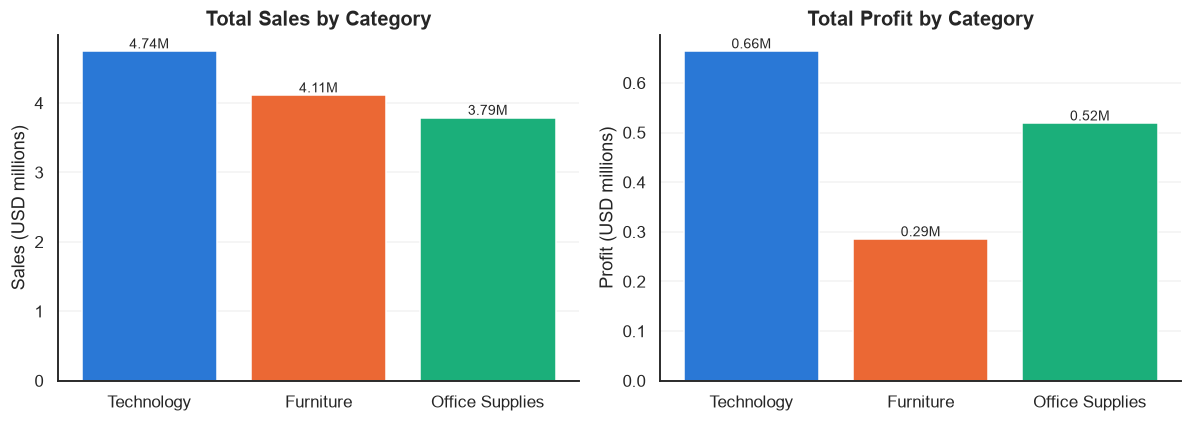

In [7]:
# ============================================================
# 7.1 AMOUNTS: Sales and Profit by Category (bar charts, strict 0-baseline)
# ============================================================
cat = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["Sales", "Profit"]):
    values = cat[col] / 1e6                            
    ax.bar(cat.index, values, color=CAT3)             
    ax.set_ylim(bottom=min(0, values.min() * 1.1))     
    ax.axhline(0, color="black", linewidth=0.8)        
    ax.set_title(f"Total {col} by Category")
    ax.set_ylabel(f"{col} (USD millions)")
    for i, v in enumerate(values):                     
        ax.text(i, v, f"{v:.2f}M", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
save(fig, "01_amounts_category")                      
plt.show()

Saved: exports/02_profit_subcategory_diverging.png and exports/02_profit_subcategory_diverging.svg


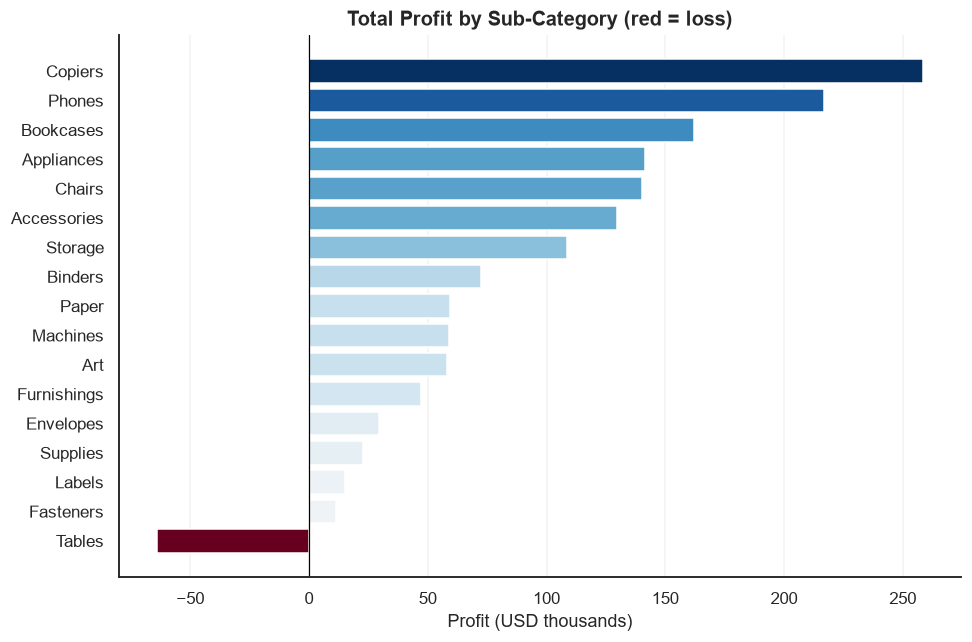

In [8]:
# ============================================================
# 7.2 AMOUNTS + DIVERGING COLOR: Profit by Sub-Category
# ============================================================
sub = df.groupby("Sub_Category")["Profit"].sum().sort_values()

norm = mpl.colors.TwoSlopeNorm(vmin=min(sub.min(), -1), vcenter=0, vmax=max(sub.max(), 1))
colors = plt.get_cmap(DIV)(norm(sub.values))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sub.index, sub.values / 1e3, color=colors, edgecolor="white")  
ax.axvline(0, color="black", linewidth=0.8)                              
ax.grid(axis="x", alpha=0.25); ax.grid(axis="y", visible=False)         
ax.set_title("Total Profit by Sub-Category (red = loss)")
ax.set_xlabel("Profit (USD thousands)")
plt.tight_layout()
save(fig, "02_profit_subcategory_diverging")                             
plt.show()

## Distributions
Histograms, KDE, box and violin plots to show shape, spread and outliers.

Saved: exports/03_hist_kde_sales.png and exports/03_hist_kde_sales.svg


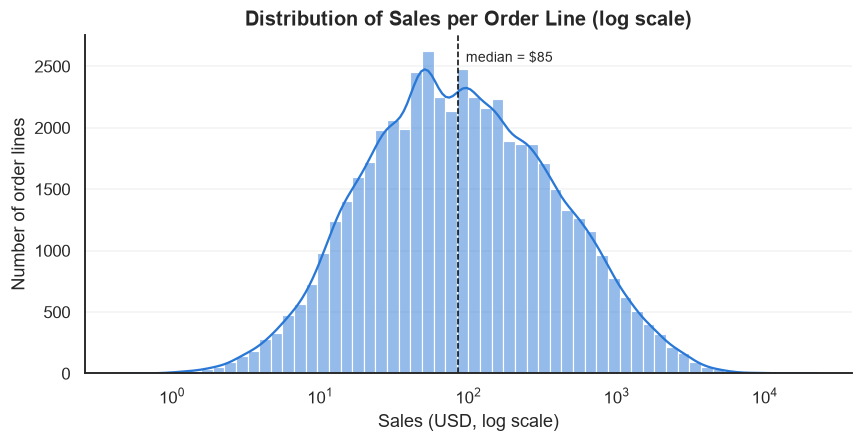

In [9]:
# ============================================================
# 8.1 DISTRIBUTION: Histogram + KDE of Sales (log scale)
# ============================================================
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df.loc[df["Sales"] > 0, "Sales"], bins=60, log_scale=True, kde=True,   
             color=CAT3[0], edgecolor="white", ax=ax)
median_sales = df["Sales"].median()                                                
ax.axvline(median_sales, color="black", linestyle="--", linewidth=1)               
ax.text(median_sales, ax.get_ylim()[1] * 0.92, f"  median = ${median_sales:,.0f}", fontsize=9)
ax.set_title("Distribution of Sales per Order Line (log scale)")
ax.set_xlabel("Sales (USD, log scale)"); ax.set_ylabel("Number of order lines")
save(fig, "03_hist_kde_sales")                                                      
plt.show()

Saved: exports/04_kde_margin_segment.png and exports/04_kde_margin_segment.svg


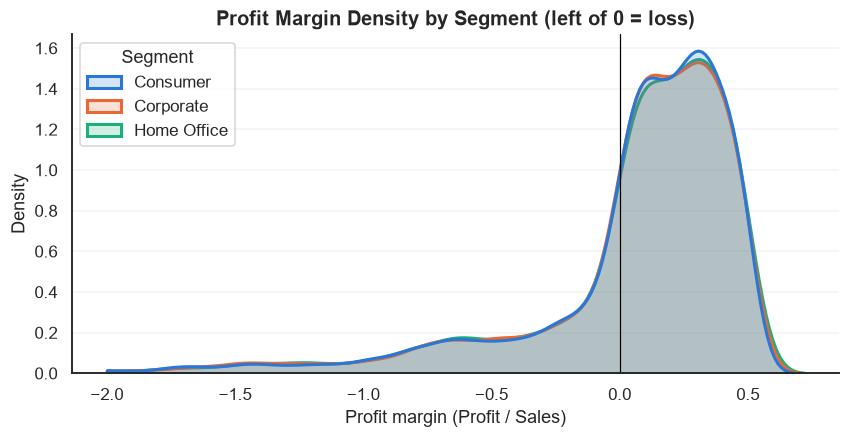

In [10]:
# ============================================================
# 8.2 DISTRIBUTION: KDE of Profit Margin by Customer Segment
# ============================================================
fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(data=df, x="Profit_Margin", hue="Segment", palette=CAT3,
            fill=True, alpha=0.2, common_norm=False,   
            clip=(-2, 1), linewidth=2, ax=ax)          
ax.axvline(0, color="black", linewidth=0.8)            
ax.set_title("Profit Margin Density by Segment (left of 0 = loss)")
ax.set_xlabel("Profit margin (Profit / Sales)")
save(fig, "04_kde_margin_segment")                    
plt.show()

Saved: exports/05_box_violin_shipdays.png and exports/05_box_violin_shipdays.svg


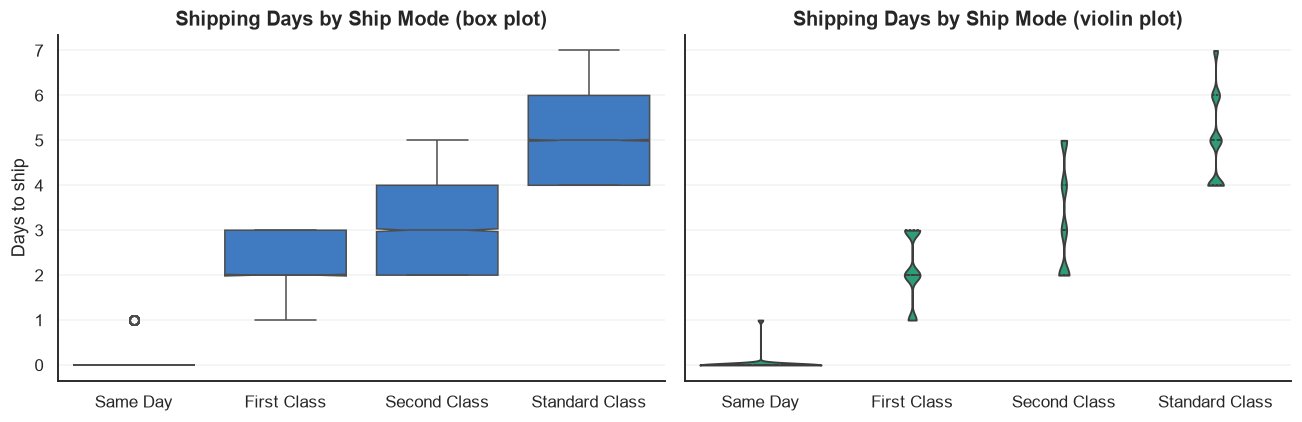

In [11]:
# ============================================================
# 8.3 DISTRIBUTION + UNCERTAINTY: Box plot (notched = 95% CI of median) and Violin plot
# ============================================================
order = df.groupby("Ship_Mode")["Ship_Days"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.boxplot(data=df, x="Ship_Mode", y="Ship_Days", order=order,
            notch=True, color=CAT3[0], ax=axes[0])        
axes[0].set_title("Shipping Days by Ship Mode (box plot)")
sns.violinplot(data=df, x="Ship_Mode", y="Ship_Days", order=order,
               color=CAT3[2], inner="quartile", cut=0, ax=axes[1])   
axes[1].set_title("Shipping Days by Ship Mode (violin plot)")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("Days to ship")
plt.tight_layout()
save(fig, "05_box_violin_shipdays")                      
plt.show()

## Uncertainty & Variability
Confidence interval bands and error bars to communicate measurement error.

Saved: exports/06_line_ci_monthly.png and exports/06_line_ci_monthly.svg


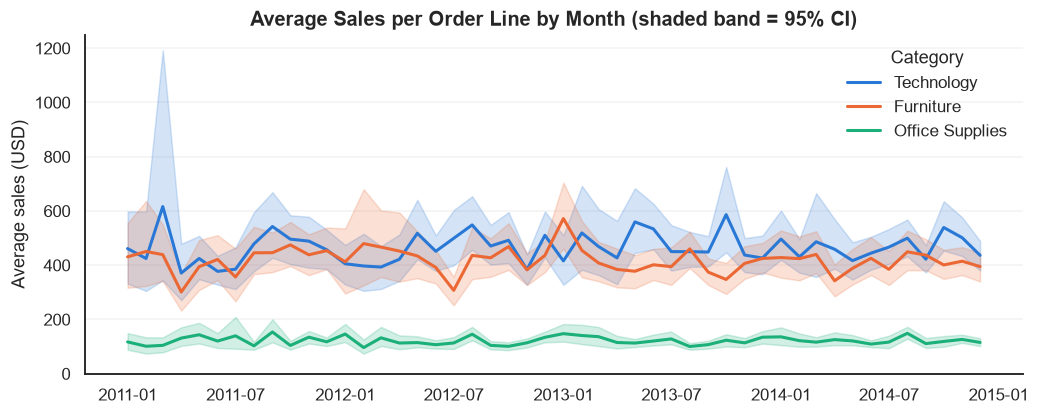

In [12]:
# ============================================================
# 9.1 UNCERTAINTY: Monthly average order value with 95% CI bands
# ============================================================
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=df, x="Year_Month", y="Sales", hue="Category", palette=CAT3,
             estimator="mean", errorbar=("ci", 95), n_boot=300, linewidth=2, ax=ax)
ax.set_ylim(bottom=0)                                  
ax.set_title("Average Sales per Order Line by Month (shaded band = 95% CI)")
ax.set_xlabel(""); ax.set_ylabel("Average sales (USD)")
ax.legend(title="Category", frameon=False)           
save(fig, "06_line_ci_monthly")                       
plt.show()

Saved: exports/07_bar_ci_discount.png and exports/07_bar_ci_discount.svg


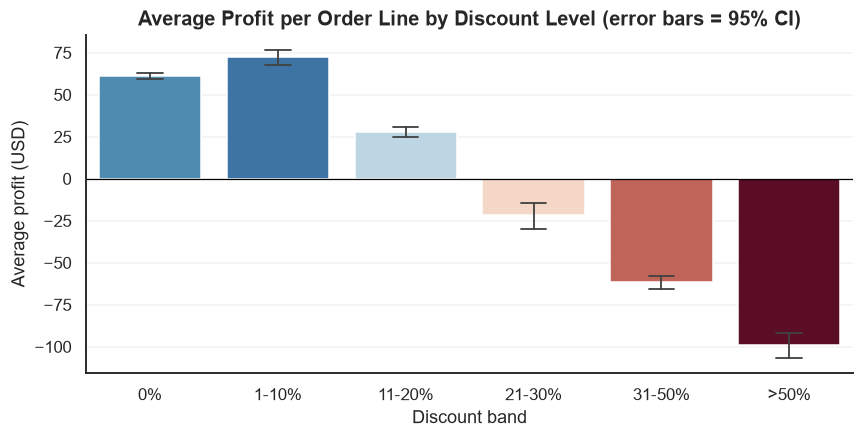

In [13]:
# ============================================================
# 9.2 UNCERTAINTY: Mean Profit by Discount Band with 95% CI error bars
# ============================================================
bands = df.groupby("Discount_Band", observed=True)["Profit"].mean()
lim = max(abs(bands.min()), abs(bands.max()))
band_norm = mpl.colors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)       
band_colors = {b: plt.get_cmap(DIV)(band_norm(v)) for b, v in bands.items()}

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=df, x="Discount_Band", y="Profit", hue="Discount_Band",
            order=list(bands.index), hue_order=list(bands.index), palette=band_colors,
            estimator="mean", errorbar=("ci", 95), n_boot=500, capsize=0.2, dodge=False,  
            err_kws={"linewidth": 1.2}, legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)            # 0-baseline
ax.set_title("Average Profit per Order Line by Discount Level (error bars = 95% CI)")
ax.set_xlabel("Discount band"); ax.set_ylabel("Average profit (USD)")
save(fig, "07_bar_ci_discount")                        
plt.show()

## Proportions (part-to-whole)
Stacked area chart and interactive treemap.

Saved: exports/08_stacked_area_market_share.png and exports/08_stacked_area_market_share.svg


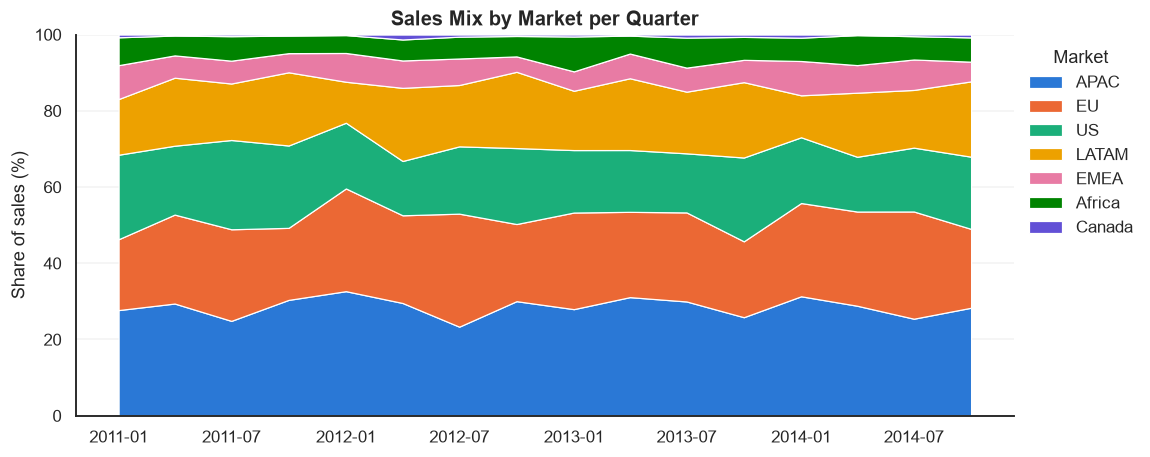

In [14]:
# ============================================================
# 10.1 PROPORTIONS: Sales share by Market over time (100% stacked area)
# ============================================================
share = df.pivot_table(index="Quarter_Start", columns="Market", values="Sales", aggfunc="sum").fillna(0)
share = share[share.sum().sort_values(ascending=False).index]      
if share.shape[1] > 7:                                              
    share["Other"] = share.iloc[:, 6:].sum(axis=1)
    share = share.iloc[:, list(range(6)) + [-1]]
share_pct = share.div(share.sum(axis=1), axis=0) * 100              

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(share_pct.index, share_pct.T.values, labels=share_pct.columns,
             colors=CAT7[:share_pct.shape[1]], edgecolor="white", linewidth=0.8)  
ax.set_ylim(0, 100); ax.set_ylabel("Share of sales (%)")
ax.set_title("Sales Mix by Market per Quarter")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, title="Market")  
save(fig, "08_stacked_area_market_share")                           
plt.show()

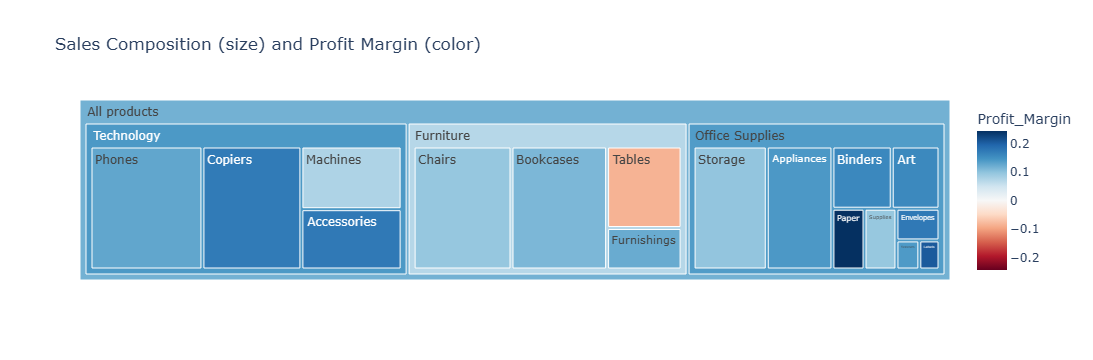

In [15]:
# ============================================================
# 10.2 PROPORTIONS (interactive): Treemap Category -> Sub-Category
# ============================================================
tm = df.groupby(["Category", "Sub_Category"], as_index=False).agg(Sales=("Sales", "sum"),
                                                                 Profit=("Profit", "sum"))
tm["Profit_Margin"] = tm["Profit"] / tm["Sales"]

fig = px.treemap(tm, path=[px.Constant("All products"), "Category", "Sub_Category"],
                 values="Sales", color="Profit_Margin",
                 color_continuous_scale="RdBu", color_continuous_midpoint=0,
                 title="Sales Composition (size) and Profit Margin (color)")
fig.write_html("exports/09_treemap_sales_margin.html")   
fig.show()

## Polar Coordinate System
Months are cyclical, so a polar chart shows seasonality naturally.

Saved: exports/10_polar_seasonality.png and exports/10_polar_seasonality.svg


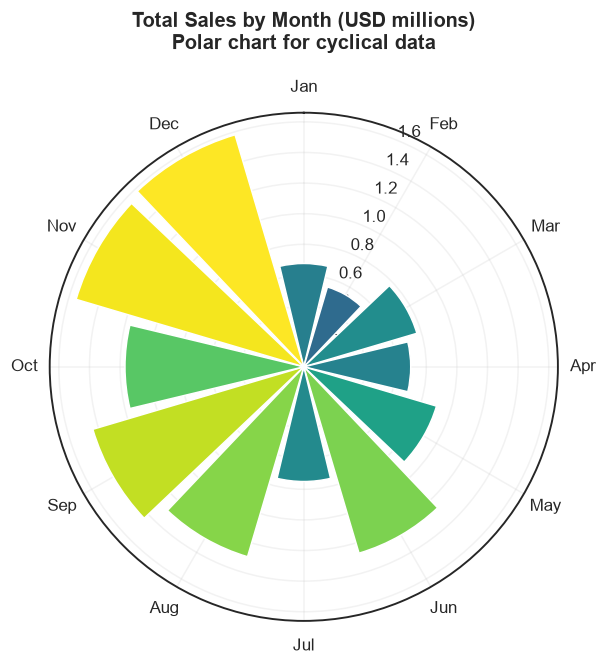

In [16]:
# ============================================================
# 11. POLAR COORDINATES: Monthly seasonality (cyclical data)
# ============================================================
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = df.groupby("Month")["Sales"].sum().reindex(range(1, 13), fill_value=0)   
angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)                             

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="polar")                                         
ax.bar(angles, monthly.values / 1e6, width=2 * np.pi / 12 * 0.9,
       color=plt.get_cmap(SEQ)(monthly.values / monthly.max()), edgecolor="white")  
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)                        
ax.set_xticks(angles); ax.set_xticklabels(month_names)
ax.set_title("Total Sales by Month (USD millions)\nPolar chart for cyclical data", pad=20)
save(fig, "10_polar_seasonality")                                                  
plt.show()

## X–Y Relationships & Correlation
Correlation heatmap (Seaborn) and interactive scatter/bubble plots (Plotly).

Saved: exports/11_correlation_heatmap.png and exports/11_correlation_heatmap.svg


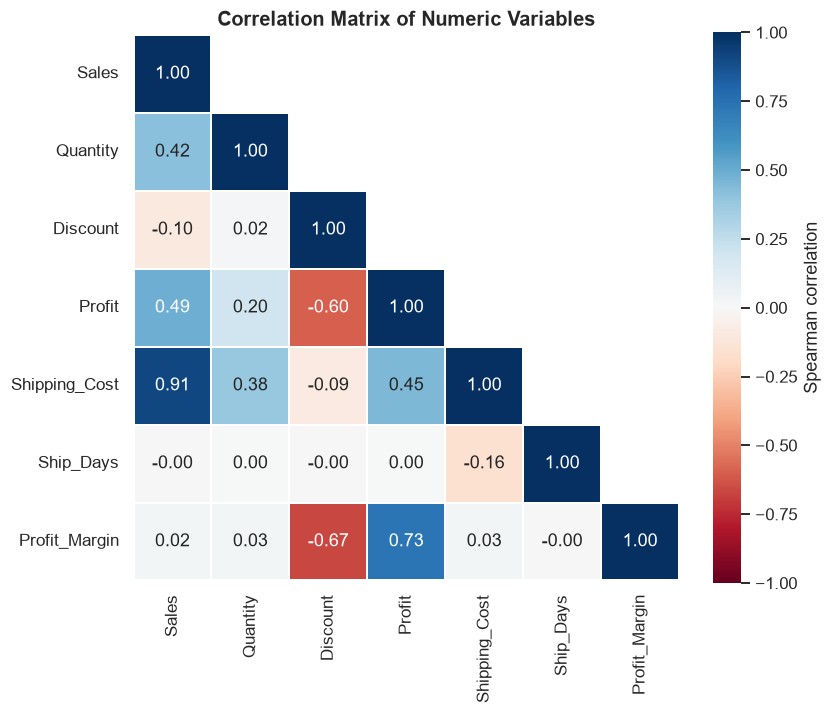

In [17]:
# ============================================================
# 12.1 X-Y RELATIONSHIPS: Correlation matrix heatmap (Seaborn)
# ============================================================
corr_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping_Cost", "Ship_Days", "Profit_Margin"]

corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)     

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",      
            cmap=DIV, vmin=-1, vmax=1, center=0,         
            square=True, linewidths=1, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation Matrix of Numeric Variables")
save(fig, "11_correlation_heatmap")                    
plt.show()

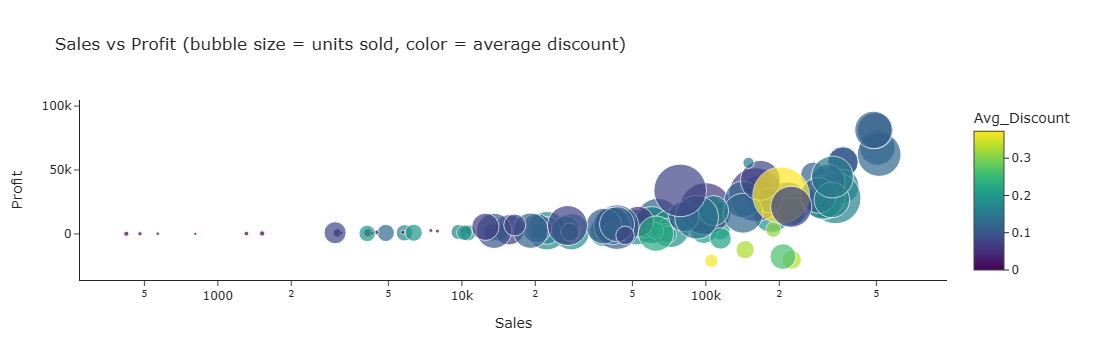

In [18]:
# ============================================================
# 12.2 X-Y RELATIONSHIPS (interactive): Bubble chart by Market and Sub-Category
# ============================================================
bub = df.groupby(["Market", "Sub_Category"], as_index=False).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum"), Avg_Discount=("Discount", "mean"))

fig = px.scatter(bub, x="Sales", y="Profit",
                 size="Quantity",                        
                 color="Avg_Discount",                  
                 hover_name="Sub_Category", hover_data=["Market"],
                 log_x=True,                             
                 size_max=40, color_continuous_scale="Viridis",
                 title="Sales vs Profit (bubble size = units sold, color = average discount)")
fig.add_hline(y=0, line_dash="dash", line_color="gray")  
fig.update_layout(template="simple_white")              
fig.write_html("exports/12_bubble_sales_profit.html")    
fig.show()

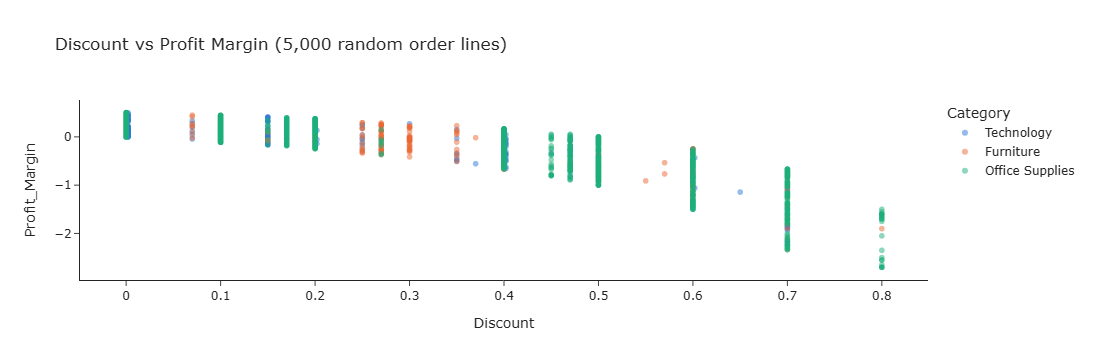

In [19]:
# ============================================================
# 12.3 X-Y RELATIONSHIPS (interactive): Discount vs Profit Margin (order level)
# ============================================================
sample = df.sample(n=min(5000, len(df)), random_state=42)    
fig = px.scatter(sample, x="Discount", y="Profit_Margin",
                 color="Category", color_discrete_sequence=CAT3,  
                 category_orders={"Category": ["Technology", "Furniture", "Office Supplies"]}, 
                 opacity=0.5,                                      
                 hover_data=["Sub_Category", "Country", "Sales", "Profit"],
                 title="Discount vs Profit Margin (5,000 random order lines)")
fig.add_hline(y=0, line_dash="dash", line_color="gray")      
fig.update_layout(template="simple_white")                      
fig.write_html("exports/13_scatter_discount_margin.html")      
fig.show()

## Geospatial Data
Choropleth map using geographic coordinates and a diverging palette centered at 0.

Countries without ISO code (not drawn): ['Guadeloupe', 'Martinique']


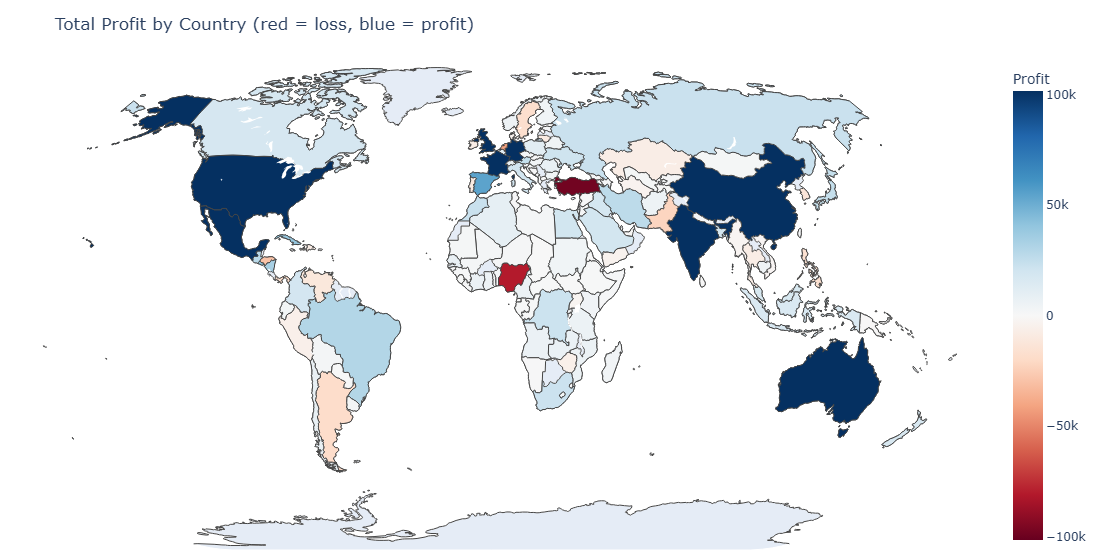

In [20]:
# ============================================================
# 13. GEOSPATIAL: Choropleth map of Profit by Country
# ============================================================
geo = df.groupby("Country", as_index=False).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))

iso = dict(zip(px.data.gapminder()["country"], px.data.gapminder()["iso_alpha"]))
iso.update({"Russia": "RUS", "South Korea": "KOR", "Democratic Republic of the Congo": "COD",
            "Republic of the Congo": "COG", "Slovakia": "SVK", "Yemen": "YEM", "Hong Kong": "HKG",
            "Myanmar (Burma)": "MMR", "Cote d'Ivoire": "CIV", "Macedonia": "MKD",
            "Ukraine": "UKR", "Kazakhstan": "KAZ", "Uzbekistan": "UZB", "Turkmenistan": "TKM",
            "Tajikistan": "TJK", "Kyrgyzstan": "KGZ", "Belarus": "BLR", "Moldova": "MDA",
            "Lithuania": "LTU", "Latvia": "LVA", "Estonia": "EST", "Georgia": "GEO",
            "Armenia": "ARM", "Azerbaijan": "AZE", "Qatar": "QAT", "United Arab Emirates": "ARE",
            "Luxembourg": "LUX", "Malta": "MLT", "Cyprus": "CYP", "Barbados": "BRB",
            "Guyana": "GUY", "Suriname": "SUR", "Bhutan": "BTN", "South Sudan": "SSD",
            "Swaziland": "SWZ", "Brunei": "BRN", "Belize": "BLZ", "Bahamas": "BHS",
            "Egypt": "EGY", "Iran": "IRN", "Syria": "SYR", "Venezuela": "VEN", "Laos": "LAO",
            "Kyrgyz Republic": "KGZ", "Czech Republic": "CZE", "Taiwan": "TWN",
            "Papua New Guinea": "PNG"})
geo["ISO3"] = geo["Country"].map(iso)
print("Countries without ISO code (not drawn):", geo.loc[geo["ISO3"].isna(), "Country"].tolist())

lim = geo["Profit"].abs().quantile(0.95)
fig = px.choropleth(geo.dropna(subset=["ISO3"]), locations="ISO3", color="Profit",
                    hover_name="Country", hover_data={"Sales": ":,.0f", "Profit": ":,.0f", "ISO3": False},
                    color_continuous_scale="RdBu", range_color=(-lim, lim),  
                    title="Total Profit by Country (red = loss, blue = profit)")
fig.update_geos(projection_type="natural earth",         
                projection_rotation=dict(lon=0),          
                showframe=False, showcountries=True, countrycolor="white")
fig.update_layout(height=550, margin=dict(l=0, r=0, t=60, b=0))   
fig.write_html("exports/14_choropleth_profit_country.html")      
fig.show()

## Key Insights
Numbers used in the executive presentation (with bootstrap 95% confidence intervals).

In [21]:
# ============================================================
# 14. KEY INSIGHTS (numbers for the presentation)
# ============================================================
rng = np.random.default_rng(42)                    

def bootstrap_ci(values, n_boot=1000):
    """95% bootstrap confidence interval for the mean."""
    values = np.asarray(values)
    means = [rng.choice(values, size=len(values), replace=True).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()

high_disc = df.loc[df["Discount"] > 0.2, "Profit"]
low_disc = df.loc[df["Discount"] <= 0.2, "Profit"]
ci_high, ci_low = bootstrap_ci(high_disc), bootstrap_ci(low_disc)

rho = df["Discount"].corr(df["Profit_Margin"], method="spearman")

mk = df.groupby("Market")[["Sales", "Profit"]].sum()
mk["Margin"] = mk["Profit"] / mk["Sales"]

peak_month = month_names[int(monthly.idxmax()) - 1]

print(f"Total sales: ${total_sales:,.0f} | Total profit: ${total_profit:,.0f} | Margin: {total_profit/total_sales:.1%}")
print(f"Order lines with a loss: {df['Is_Loss'].mean():.1%}")
print("Top 3 sub-categories by profit:", sub.tail(3)[::-1].round(0).to_dict())
print("Bottom 3 sub-categories by profit:", sub.head(3).round(0).to_dict())
print(f"Avg profit, discount > 20%: ${high_disc.mean():,.1f} (95% CI {ci_high[0]:,.1f} to {ci_high[1]:,.1f})")
print(f"Avg profit, discount <= 20%: ${low_disc.mean():,.1f} (95% CI {ci_low[0]:,.1f} to {ci_low[1]:,.1f})")
print(f"Spearman correlation Discount vs Profit Margin: {rho:.2f}")
print("Best market by margin:", mk["Margin"].idxmax(), f"({mk['Margin'].max():.1%})")
print("Worst market by margin:", mk["Margin"].idxmin(), f"({mk['Margin'].min():.1%})")
print("5 countries with the biggest losses:", geo.nsmallest(5, "Profit").set_index("Country")["Profit"].round(0).to_dict())
print("Peak sales month:", peak_month)

Total sales: $12,642,502 | Total profit: $1,467,457 | Margin: 11.6%
Order lines with a loss: 24.5%
Top 3 sub-categories by profit: {'Copiers': 258568.0, 'Phones': 216717.0, 'Bookcases': 161924.0}
Bottom 3 sub-categories by profit: {'Tables': -64083.0, 'Fasteners': 11525.0, 'Labels': 15011.0}
Avg profit, discount > 20%: $-71.9 (95% CI -75.5 to -68.4)
Avg profit, discount <= 20%: $57.1 (95% CI 55.6 to 58.6)
Spearman correlation Discount vs Profit Margin: -0.67
Best market by margin: Canada (26.6%)
Worst market by margin: EMEA (5.4%)
5 countries with the biggest losses: {'Turkey': -98447.0, 'Nigeria': -80751.0, 'Netherlands': -41070.0, 'Honduras': -29482.0, 'Pakistan': -22447.0}
Peak sales month: Dec


## Conclusions
1. **High sales ≠ high profit.** Furniture is the 2nd category in sales (USD 4.11M) but the lowest in profit (USD 0.29M). The main cause is **Tables**, the only sub-category with a loss (USD -64K).
2. **Discounts above 20% destroy profit.** Order lines with discount > 20% lose **\$71.9 on average** (95% CI -75.5 to -68.4), while lines with ≤ 20% earn **\$57.1** (95% CI 55.6 to 58.6). The correlation between discount and profit margin is **-0.67**, and discounts barely affect sales (ρ = -0.10).
3. **Losses are concentrated geographically.** Turkey (USD -98K), Nigeria (USD -81K) and Netherlands (USD -41K) generate the biggest losses; EMEA has the lowest margin (5.4%).
4. **Strong seasonality.** November and December are the strongest months; shipping times are consistent and do not affect profit.

## Recommendations
- Cap discounts at **20%** (require approval above that level).
- Review pricing and discounts for **Tables**, or reduce its catalog.
- Audit discount policies in **Turkey, Nigeria and Netherlands**.
- Plan inventory and campaigns for **Q4** without deep discounts.